# Inferencia con datos que no son independientes

**Avanzado · Jornada 1 · Bloque 1.4 · diapositivas demo-tarifa, tarifa-resultado, datos-independientes, efecto-intervalo, cuarenta-bases, holm-fdr, did, paralelas, did-cuenta y ejercicio-did**

¿Funcionó el abono rebajado? ¿Cambió algo el protocolo de limpieza en alguna base? ¿Cuánta energía
ahorraron los cargadores nuevos de B-17? Tres preguntas en las que el contraste de manual se pasa de
optimista: datos autocorrelacionados, comparaciones múltiples y efectos que no son «causados por nosotros».

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

El 18 de mayo de 2026 BiciCiudad rebajó el precio del abono. Dirección quiere saber si funcionó.
Tomamos los viajes diarios del sistema, 90 días antes y 90 después, y hacemos lo que haría
cualquiera: un contraste t de diferencia de medias.

> **Mensaje clave del bloque:** «significativo» no es lo mismo que «importante», y casi nunca es
> lo mismo que «causado por nosotros».

In [2]:
# Ayudas de formato en español: números, porcentajes, fechas y ejes.


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha como en las diapositivas: 18-5-2026."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"


import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def eje_es(ax, eje="y", decimales=0, sufijo=""):
    """Etiquetas de un eje con números en español."""
    formato = FuncFormatter(lambda v, _: n(v, decimales) + sufijo)
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formato)


def eje_meses(ax, meses=(1, 4, 7, 10)):
    """Eje de fechas con el mes en español: «ene 2026»."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=meses))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{MESES[mdates.num2date(v).month - 1]} {mdates.num2date(v).year}"))

## 1. Los datos: viajes diarios antes y después

In [3]:
import statsmodels.api as sm
from scipy import stats

fecha_cambio = pd.Timestamp("2026-05-18")
dias = 90   # ← días a cada lado del cambio

horarios = pd.read_csv(DATOS / "uso_meteo" / "viajes_sistema_hora.csv")
viajes_dia = horarios.groupby("fecha_local")["viajes"].sum()
viajes_dia.index = pd.to_datetime(viajes_dia.index)

antes = viajes_dia[fecha_cambio - pd.Timedelta(days=dias):fecha_cambio - pd.Timedelta(days=1)]
despues = viajes_dia[fecha_cambio:fecha_cambio + pd.Timedelta(days=dias - 1)]
print(f"Antes: {len(antes)} días, media {n(antes.mean())} viajes al día")
print(f"Después: {len(despues)} días, media {n(despues.mean())} viajes al día")
print(f"Diferencia: +{n(despues.mean() - antes.mean())} viajes al día ({pct(despues.mean() / antes.mean() - 1)})")

Antes: 90 días, media 14.202 viajes al día
Después: 90 días, media 16.097 viajes al día
Diferencia: +1.895 viajes al día (13,3 %)


## 2. Demo, primera celda: el contraste t de siempre

In [4]:
p_ingenuo = stats.ttest_ind(despues, antes).pvalue
print(f"Contraste t: p = {n(p_ingenuo, 4)}")

Contraste t: p = 0,0008


Menor que una milésima. Muy significativo. Ya tenemos titular.

**Antes de ejecutar la celda siguiente, una apuesta.** Vamos a repetir exactamente el mismo
contraste, con los mismos datos y la misma diferencia de medias, pero calculando el error de otra
forma: con **errores HAC** (Newey-West), robustos a la autocorrelación, que tienen en cuenta que
cada día se parece al anterior. ¿Qué pasará con el p-valor? ¿Cambiará mucho, poco o nada?

Truco: la diferencia de medias es el coeficiente de una regresión de los viajes sobre una variable
que vale 0 antes y 1 después. Así se le puede pedir a la regresión el error que queramos.

In [5]:
desfases_hac = 14   # ← días de autocorrelación que se tienen en cuenta: probad 0, 7, 28

y = np.r_[antes.to_numpy(), despues.to_numpy()].astype(float)
X = sm.add_constant(np.r_[np.zeros(len(antes)), np.ones(len(despues))])
ingenua = sm.OLS(y, X).fit()
hac = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": desfases_hac})

print(f"Diferencia estimada: {n(hac.params[1])} viajes al día (la misma en las dos)")
print(f"p ingenuo = {n(ingenua.pvalues[1], 4)}   ·   p con HAC ({desfases_hac} desfases) = {n(hac.pvalues[1], 2)}")

Diferencia estimada: 1.895 viajes al día (la misma en las dos)
p ingenuo = 0,0008   ·   p con HAC (14 desfases) = 0,18


De «certeza absoluta» a «no podemos descartar que sea casualidad». **Con los mismos datos.**

La pregunta de fondo es: ¿cuántos datos independientes tenemos de verdad? El contraste t cree que
tiene 180 días sueltos. Pero si hace buen tiempo una semana, todos los días de esa semana suben
juntos.

In [6]:
rho = antes.autocorr(1)
# Cuenta de servilleta para una serie AR(1): n_efectivo ≈ n × (1 − ρ) / (1 + ρ).
n_efectivo = len(y) * (1 - rho) / (1 + rho)
print(f"Autocorrelación de un día en el «antes»: {n(rho, 2)}")
print(f"Días que cree tener el contraste t: {len(y)}; información equivalente a unos {n(n_efectivo)} días independientes")

Autocorrelación de un día en el «antes»: 0,50
Días que cree tener el contraste t: 180; información equivalente a unos 59 días independientes


En la diapositiva `datos-independientes`: **t = diferencia ÷ EE**. El numerador es el mismo en los
dos contrastes; lo que cambia es el error estándar (EE) del denominador.

In [7]:
for nombre, modelo in [("ingenuo", ingenua), (f"HAC ({desfases_hac} desfases)", hac)]:
    print(f"{nombre:>17}: EE = {n(modelo.bse[1])}  ·  t = {n(hac.params[1])} ÷ {n(modelo.bse[1])} "
          f"= {n(modelo.tvalues[1], 2)}  ·  p = {n(modelo.pvalues[1], 4)}")
print(f"El EE con HAC es {n(hac.bse[1] / ingenua.bse[1], 1)} veces el ingenuo; "
      f"la regla de servilleta decía √(180 ÷ {n(n_efectivo)}) = {n(np.sqrt(len(y) / n_efectivo), 1)}")

          ingenuo: EE = 558  ·  t = 1.895 ÷ 558 = 3,40  ·  p = 0,0008
HAC (14 desfases): EE = 1.408  ·  t = 1.895 ÷ 1.408 = 1,35  ·  p = 0,1783
El EE con HAC es 2,5 veces el ingenuo; la regla de servilleta decía √(180 ÷ 59) = 1,7


## 3. Cuánto y con qué margen

El p-valor solo dice si la diferencia podría ser casualidad. Quien decide necesita **cuánto** y
**con qué margen** (diapositiva `efecto-intervalo`).

In [8]:
ic_ingenuo = ingenua.conf_int()[1]
ic_hac = hac.conf_int()[1]
print(f"Efecto: +{n(hac.params[1])} viajes al día")
print(f"  IC 95 % ingenuo: de {n(ic_ingenuo[0])} a {n(ic_ingenuo[1])}")
print(f"  IC 95 % HAC:     de {n(ic_hac[0])} a {n(ic_hac[1])}")

Efecto: +1.895 viajes al día
  IC 95 % ingenuo: de 795 a 2.996
  IC 95 % HAC:     de −865 a 4.655


### Otra forma, sin fórmulas: el bootstrap por bloques

El bootstrap normal coge días al azar, con repetición, y recalcula la diferencia muchas veces;
pero al coger días sueltos rompe la autocorrelación. El **bootstrap por bloques** corta cada
tramo en semanas y remuestrea semanas enteras: dentro de cada semana, los días siguen pegados como
en la realidad.

In [9]:
tamano_bloque = 7   # ← días por bloque (1 = bootstrap normal, día a día)
replicas = 1000     # ← número de réplicas
generador = np.random.default_rng(2026)


def bootstrap_diferencias(bloque):
    """Diferencias de medias (después − antes) remuestreando bloques dentro de cada tramo."""
    trozos_antes = [antes.to_numpy()[i:i + bloque] for i in range(0, len(antes), bloque)]
    trozos_despues = [despues.to_numpy()[i:i + bloque] for i in range(0, len(despues), bloque)]
    diferencias = []
    for _ in range(replicas):
        a = np.concatenate([trozos_antes[j] for j in generador.integers(0, len(trozos_antes), len(trozos_antes))])
        d = np.concatenate([trozos_despues[j] for j in generador.integers(0, len(trozos_despues), len(trozos_despues))])
        diferencias.append(d.mean() - a.mean())
    return np.array(diferencias)


dif_dias = bootstrap_diferencias(1)
dif_bloques = bootstrap_diferencias(tamano_bloque)
for nombre, d in [("día a día", dif_dias), (f"bloques de {tamano_bloque} días", dif_bloques)]:
    bajo, alto = np.percentile(d, [2.5, 97.5])
    print(f"IC 95 % bootstrap {nombre}: de {n(bajo)} a {n(alto)}")

IC 95 % bootstrap día a día: de 890 a 3.035
IC 95 % bootstrap bloques de 7 días: de −193 a 3.893


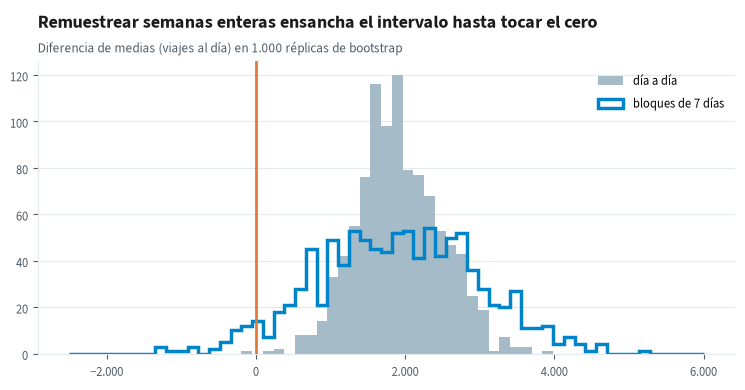

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bordes = np.linspace(-2500, 6000, 60)
ax.hist(dif_dias, bins=bordes, color=estilo.GRIS, label="día a día")
ax.hist(dif_bloques, bins=bordes, histtype="step", color=estilo.AZUL, linewidth=2.5,
        label=f"bloques de {tamano_bloque} días")
ax.axvline(0, color=estilo.NARANJA, linewidth=2)
eje_es(ax, eje="x")
ax.legend(loc="upper right")
ax.set_title("Remuestrear semanas enteras ensancha el intervalo hasta tocar el cero")
estilo.subtitulo(ax, f"Diferencia de medias (viajes al día) en {n(replicas)} réplicas de bootstrap")
plt.show()

## 4. Y el +13 % es sobre todo la época del año, no la tarifa

Incluso si el p-valor fuera fiable, la pregunta de dirección no está contestada. Comparar
mayo-agosto con febrero-mayo mezcla la tarifa con la primavera, las vacaciones y todo lo demás que
cambió a la vez. Mirad las mismas fechas **un año antes**, cuando no cambió ninguna tarifa:

In [11]:
cambio_2025 = fecha_cambio - pd.DateOffset(years=1)
antes_2025 = viajes_dia[cambio_2025 - pd.Timedelta(days=dias):cambio_2025 - pd.Timedelta(days=1)]
despues_2025 = viajes_dia[cambio_2025:cambio_2025 + pd.Timedelta(days=dias - 1)]
print(f"2025, sin cambio de tarifa: {pct(despues_2025.mean() / antes_2025.mean() - 1)}")
print(f"2026, con el abono rebajado: {pct(despues.mean() / antes.mean() - 1)}")

2025, sin cambio de tarifa: 5,0 %
2026, con el abono rebajado: 13,3 %


Sin tocar nada, las mismas fechas ya subieron un 5 % en 2025. Y la diferencia entre los dos años
tampoco es el efecto de la tarifa: otro año trae otra primavera y otro tiempo. Como los datos son
sintéticos, sabemos la verdad: **el abono rebajado solo sumó un 3 %**.

Para separar una cosa de la otra hace falta un **grupo de comparación** que viva lo mismo en el
mismo periodo. Es la idea de las **diferencias en diferencias**, que usaréis en el ejercicio de
B-17 (apartado 6). Antes, la otra trampa del bloque.

## 5. Cuarenta bases y alguna saldrá «significativa» por azar

El 10 de febrero de 2025 se implantó en todas las bases un nuevo protocolo de limpieza. En cada
una de las 40 bases, un contraste t del mínimo nocturno de las cuatro semanas anteriores frente a
las cuatro siguientes (diapositiva `cuarenta-bases`). Sabemos la verdad: el protocolo no cambió nada.

In [12]:
from statsmodels.stats.multitest import multipletests

alfa = 0.05   # ← nivel de cada contraste (y de Holm)
fdr = 0.10    # ← proporción de falsos descubrimientos tolerada (Benjamini-Hochberg)

diario = pd.read_csv(DATOS / "energia_bases" / "diario.csv", parse_dates=["fecha"])
nocturno = diario.pivot(index="fecha", columns="base_id", values="minimo_nocturno_kw")

t0 = pd.Timestamp("2025-02-10")
p_valores = {}
for base in nocturno.columns:
    previo = nocturno[base][t0 - pd.Timedelta(days=28):t0 - pd.Timedelta(days=1)]
    posterior = nocturno[base][t0:t0 + pd.Timedelta(days=27)]
    p_valores[base] = stats.ttest_ind(posterior, previo).pvalue

tabla = pd.Series(p_valores).sort_values().to_frame("p")
m = len(tabla)
tabla["umbral Holm"] = alfa / (m - np.arange(m))           # 0,05/40, 0,05/39…
tabla["umbral BH"] = fdr * np.arange(1, m + 1) / m          # 0,10 × 1/40, 0,10 × 2/40…
tabla["Holm"] = multipletests(tabla["p"], alpha=alfa, method="holm")[0]
tabla["BH"] = multipletests(tabla["p"], alpha=fdr, method="fdr_bh")[0]

print(f"Bases con p < {n(alfa, 2)} sin corregir: {(tabla['p'] < alfa).sum()} (esperables por azar: {n(alfa * m)})")
print(f"Significativas con Holm: {tabla['Holm'].sum()}   ·   con Benjamini-Hochberg (FDR {pct(fdr, 0)}): {tabla['BH'].sum()}")
tabla.head(5).round(5)

Bases con p < 0,05 sin corregir: 2 (esperables por azar: 2)
Significativas con Holm: 0   ·   con Benjamini-Hochberg (FDR 10 %): 0


,p,umbral Holm,umbral BH,Holm,BH
B-19,0.00742,0.00125,0.0025,False,False
B-37,0.02792,0.00128,0.0050,False,False
B-25,0.09743,0.00132,0.0075,False,False
B-28,0.15374,0.00135,0.0100,False,False
B-18,0.18731,0.00139,0.0125,False,False


Dos bases por debajo de 0,05 en un protocolo que no hizo nada: dos titulares falsos. Con 40
contrastes al 5 %, lo esperable son unos dos. Exactamente las gominolas de xkcd.

- **Holm** (que no se cuele ni uno) compara el p-valor más pequeño con 0,05/40 = 0,00125. Para
  decisiones caras: cambiar un cargador, abrir una investigación.
- **Benjamini-Hochberg** (que no sean demasiados) controla la proporción de falsos entre los
  señalados. Para cribar candidatas.

Holm para decidir, FDR para buscar. Y, sobre todo, contad cuántos contrastes habéis hecho,
incluidos los que no salieron y nadie reportó.

## 6. Ejercicio: ¿cuánta energía ahorró cambiar los cargadores de B-17? (22 min, en parejas)

El 1 de octubre de 2025 se cambiaron los cargadores de B-17 por otros más eficientes. Comparables:
B-13, B-15, B-16 y B-18, de tamaño y uso parecidos. Variable: **energía no contabilizada** (lo que
entra en la base menos lo que las baterías dicen haber recibido), en kWh al día. Doce meses antes y
doce después.

**Antes de medir, mirad si iban en paralelo** (diapositiva `paralelas`).

In [13]:
comparables = ["B-13", "B-15", "B-16", "B-18"]
fecha_cargadores = pd.Timestamp("2025-10-01")

no_contabilizada = diario.pivot(index="fecha", columns="base_id", values="no_contabilizada_kwh")
mes = no_contabilizada.resample("MS").mean()
mes_antes = mes[:fecha_cargadores - pd.Timedelta(days=1)]
mes_despues = mes[fecha_cargadores:]

distancia = mes_antes["B-17"] - mes_antes[comparables].mean(axis=1)
print(f"Antes del cambio, B-17 va {n(distancia.mean())} kWh al día por encima de sus comparables;")
print(f"esa distancia varía de un mes a otro con una desviación típica de {n(distancia.std(), 1)} kWh.")

Antes del cambio, B-17 va 60 kWh al día por encima de sus comparables;
esa distancia varía de un mes a otro con una desviación típica de 3,2 kWh.


**Paso 1. Estimar con DiD.** Cuánto cambió B-17 (media de los 12 meses después menos la de los 12
antes) **menos** cuánto cambiaron las comparables en el mismo periodo. Todo lo que afectó a las
dos (la estación, el tiempo, la tarifa) se resta solo. Pensad en el signo: si los cargadores nuevos
funcionan, la pérdida baja.

In [14]:
cambio_b17 = mes_despues["B-17"].mean() - mes_antes["B-17"].mean()
cambio_comparables = 0   # COMPLETAD: lo mismo para la media de las cuatro comparables

efecto_did = cambio_b17 - cambio_comparables
print(f"Cambio de B-17: {n(cambio_b17)} kWh al día · de las comparables: {n(cambio_comparables)}")
print(f"Efecto estimado: {n(efecto_did)} kWh al día")

Cambio de B-17: −183 kWh al día · de las comparables: 0
Efecto estimado: −183 kWh al día


**Paso 2. Dar el intervalo.** Un efecto sin intervalo no se entrega. La misma cuenta, día a día,
como regresión: la diferencia diaria entre B-17 y la media de sus comparables, frente a una
variable que vale 0 antes del cambio y 1 después. El coeficiente es la DiD; con errores HAC,
porque los días no son independientes.

In [15]:
diferencia_diaria = no_contabilizada["B-17"] - no_contabilizada[comparables].mean(axis=1)
despues_del_cambio = (diferencia_diaria.index >= fecha_cargadores).astype(float)
did = sm.OLS(diferencia_diaria.to_numpy(), sm.add_constant(despues_del_cambio)).fit(
    cov_type="HAC", cov_kwds={"maxlags": desfases_hac})
ic_did = did.conf_int()[1]
print(f"DiD diaria: {n(did.params[1])} kWh al día (IC 95 % HAC de {n(ic_did[0])} a {n(ic_did[1])})")

DiD diaria: −189 kWh al día (IC 95 % HAC de −194 a −183)


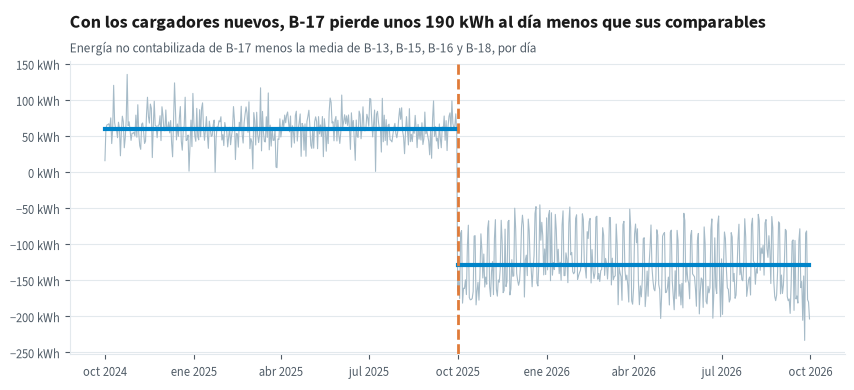

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(diferencia_diaria.index, diferencia_diaria.values, color=estilo.GRIS, linewidth=0.8)
tramo_antes = diferencia_diaria[:fecha_cargadores - pd.Timedelta(days=1)]
tramo_despues = diferencia_diaria[fecha_cargadores:]
for tramo in (tramo_antes, tramo_despues):
    ax.plot([tramo.index[0], tramo.index[-1]], [tramo.mean()] * 2, color=estilo.AZUL, linewidth=3)
ax.axvline(fecha_cargadores, color=estilo.NARANJA, linestyle="--")
eje_es(ax, sufijo=" kWh")
eje_meses(ax)
ax.set_title(f"Con los cargadores nuevos, B-17 pierde unos {n(round(-did.params[1], -1))} kWh al día menos que sus comparables")
estilo.subtitulo(ax, "Energía no contabilizada de B-17 menos la media de B-13, B-15, B-16 y B-18, por día")
plt.show()

**Paso 3. Discutir el supuesto.** La DiD se sostiene en las **tendencias paralelas**: que, sin el
cambio, B-17 habría seguido moviéndose como sus comparables. Solo se puede comprobar en el «antes».
Una forma: una **prueba placebo**. Fingimos que el cambio fue en otra fecha, usando solo los meses
anteriores al de verdad. Si sale un «efecto», las líneas no iban en paralelo.

In [17]:
fecha_placebo = pd.Timestamp("2025-04-01")   # ← una fecha cualquiera antes del cambio real

solo_antes = diferencia_diaria[:fecha_cargadores - pd.Timedelta(days=1)]
placebo = sm.OLS(solo_antes.to_numpy(),
                 sm.add_constant((solo_antes.index >= fecha_placebo).astype(float))).fit(
    cov_type="HAC", cov_kwds={"maxlags": desfases_hac})
ic_placebo = placebo.conf_int()[1]
print(f"«Efecto» placebo el {fecha(fecha_placebo)}: {n(placebo.params[1], 1)} kWh al día "
      f"(IC 95 % de {n(ic_placebo[0], 1)} a {n(ic_placebo[1], 1)}; p = {n(placebo.pvalues[1], 2)})")

# La misma cuenta con las cuatro medias (diapositiva did-cuenta).
b17_pre = no_contabilizada["B-17"][:fecha_cargadores - pd.Timedelta(days=1)]
comp_pre = no_contabilizada[comparables].mean(axis=1)[:fecha_cargadores - pd.Timedelta(days=1)]
hasta_placebo = fecha_placebo - pd.Timedelta(days=1)
medias_placebo = [b17_pre[fecha_placebo:].mean(), b17_pre[:hasta_placebo].mean(),
                  comp_pre[fecha_placebo:].mean(), comp_pre[:hasta_placebo].mean()]
a, b, c, d = medias_placebo
print(f"({n(a, 2)} − {n(b, 2)}) − ({n(c, 2)} − {n(d, 2)}) = {n(a - b, 2)} − {n(c - d, 2)} = {n(a - b - (c - d), 2)}")

«Efecto» placebo el 1-4-2025: 1,0 kWh al día (IC 95 % de −3,2 a 5,3; p = 0,63)
(864,65 − 837,61) − (804,32 − 778,32) = 27,04 − 26,00 = 1,04


Para la puesta en común, cada pareja dice su cifra, su intervalo y **una frase que pondría en el
informe**. Y la discusión: ¿os basta con que fueran en paralelo antes? ¿Qué otras cosas pudieron
cambiar en B-17 ese mismo mes? ¿Las comparables son de verdad comparables?

## Qué os lleváis

- Con datos que vienen en el tiempo o en grupos, el contraste de manual se pasa de optimista:
  p = 0,0008 se convierte en p = 0,18 con los mismos datos.
- Di cuánto y con qué margen (HAC o bootstrap por bloques), no solo si es significativo.
- Si pruebas 40 bases, alguna saldrá por azar: Holm para decidir, FDR para buscar.
- Sin un grupo de comparación, una diferencia antes-después mezcla tu cambio con todo lo demás.
  La DiD lo separa si las tendencias iban en paralelo, y eso hay que mirarlo.
- **«Significativo» no es lo mismo que «importante», y casi nunca es lo mismo que «causado por nosotros».**